# FoodShock V9 | MLSC 2026
**Cross-Country ASEAN Food Price Forecasting & Early Shock Detection**  
Preliminary round · SDG 2 (Zero Hunger), target 2.c

FoodShock supports market-investigation prioritization when staple food prices may rise sharply. A shock is a next-month price increase strictly greater than 5% (numerical tolerance 1e-12). The system combines a residual point forecast, calibrated quantile intervals, and a balanced classifier risk score with a validation-selected hybrid alert. It is a historical decision-support prototype, not a live service or guaranteed alert.

This executed notebook reads V9 artifacts from the canonical full benchmark. The original V8 metrics and code are archived under `legacy/`, not mixed with V9 results.

In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'data' / 'v9_manifest.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'v9_manifest.json').exists(), 'Open from the project root or notebooks folder.'
sys.path.insert(0, str(ROOT))
from core.models import validate_panel, split_panel, predict_two_stage
from core.model_store import verify_results, load_bundle
from core.utils import FEATURE_COLS, CAT_COLS, price_change, shock_event, alert_mask, classify_shock
D = ROOT / 'data'
M = verify_results(D)
print('V9 artifacts verified:', M['dataset_sha256'])
print('Trials per tuned model per fold:', M['trials_per_tuned_model'])
print('Versions:', M['versions'])

V9 artifacts verified: ad9fefd80643b0b2d35f4301b02ff2b1c62f0ea4b0ee2789a6e31e8eeaf018c1
Trials per tuned model per fold: 25
Versions: {'python': '3.13.5', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'lightgbm': '4.6.0', 'xgboost': '3.1.3', 'catboost': '1.2.8', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'optuna': '4.8.0', 'joblib': '1.5.3'}


## 1. Data provenance and integrity
The packaged model-ready panel derives from the [Global Food Prices Database (WFP) on Kaggle](https://www.kaggle.com/datasets/abhishekgupta56447/global-food-prices-database-wfp). The exact original raw snapshot, extraction date and license were not present. `docs/DATA_SOURCES.md` records resource-discovery instructions and unresolved metadata. No fabricated raw data is used. Preprocessing ensures consistent regional gap values; observed prices and labels are unchanged. Source series eligibility (>=60 months) is retrospective and reporting availability is not verified. All numeric features and encodings are explicit; target columns are excluded.

In [2]:
panel = validate_panel(pd.read_csv(D / 'foodshock_asean_model_ready.csv'))
print('Shape:', panel.shape, '| Date range:', panel.date.min().date(), 'to', panel.date.max().date())
print('Series:', panel.series_id.nunique(), '| Missing:', int(panel.isna().sum().sum()), '| Duplicates:', int(panel.duplicated(['series_id','date']).sum()))
display(panel.groupby('countryiso3').agg(rows=('series_id','size'), series=('series_id','nunique'), shock_rate=('shock_label','mean')).assign(row_share=lambda x: x.rows/len(panel)))
display(panel.target_pct_change_t1.quantile([.25,.75,.9,.95]).rename('descriptive return quantiles'))
display(panel[['date','countryiso3','market','commodity_group','usdprice','lag_1','target_price_usd_t1','shock_label']].head())
print('Model numeric features:', FEATURE_COLS)
print('Categorical columns:', CAT_COLS)

Shape: (27950, 39) | Date range: 2016-02-01 to 2025-11-01
Series: 582 | Missing: 0 | Duplicates: 0


,rows,series,shock_rate,row_share
countryiso3,,,,
IDN,3904,100,0.103227,0.139678
KHM,2882,69,0.140527,0.103113
LAO,4329,82,0.093786,0.154884
MMR,205,17,0.204878,0.007335
PHL,16285,305,0.065213,0.582648
THA,98,2,0.142857,0.003506
TLS,247,7,0.190283,0.008837


0.25   -0.018903
0.75    0.017741
0.90    0.044350
0.95    0.072000
Name: descriptive return quantiles, dtype: float64

,date,countryiso3,market,commodity_group,usdprice,lag_1,target_price_usd_t1,shock_label
0,2016-02-01,IDN,National Average,Beef Meat,7.87,7.50,8.02,0
1,2016-02-01,IDN,National Average,Chicken Meat,2.98,2.98,2.75,0
2,2016-02-01,IDN,National Average,Cooking Oil,1.00,0.96,1.02,0
3,2016-02-01,IDN,National Average,Rice,1.00,0.96,1.01,0
4,2016-02-01,KHM,Banteay Meanchey,Rice,0.35,0.35,0.35,0


Model numeric features: ['usdprice', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_std_6', 'rolling_min_6', 'rolling_max_6', 'price_to_mean6', 'cv_6', 'pct_change_1m', 'pct_change_3m', 'pct_change_12m', 'month_sin', 'month_cos', 'fx_pct_1m', 'fx_pct_3m', 'fx_vol_6m', 'asean_comm_mom_1m', 'country_vs_asean_mom']
Categorical columns: ['countryiso3', 'commodity_group', 'pricetype']


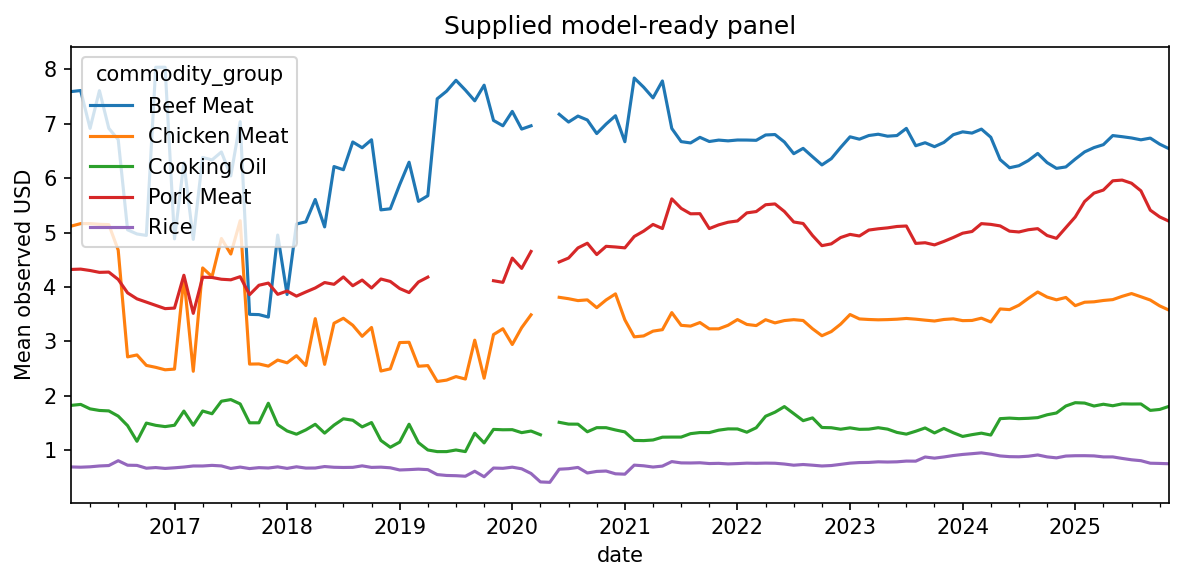

In [3]:
display(Image(filename=str(ROOT / 'figures' / 'eda_trends.png'), width=820))

## 2. Temporal methodology
At forecast origin t, the current price is observed; historical price features use t−1 or earlier. The label belongs to t+1. Train labels must mature strictly before the next block begins. Every outer fold reserves the final approximately 20% of training months as calibration; tuning is inside an earlier purged validation block. All three system models are frozen before calibration. There are no random row splits. Category encoders fit on the fit block; unseen categories map to −1 in OOS.

Point: predict residual Δy = y(t+1) − y(t), reconstruct y(t+1) and clip at zero. Quantiles: LightGBM residual quantiles .1/.9, calibrated via finite-sample expansion; empirical coverage target 80%, not guaranteed under panel dependence. Stage 2: balanced LightGBM score; select a threshold on calibration with the exact frozen point model, maximizing recall subject to precision >=20%, otherwise F0.5. Hybrid ALERT = score ≥ threshold OR predicted rise >5%. The score is not a calibrated probability.

The supplied data has retrospective coverage selection and possible reporting delays. The split rules control temporal label overlap, not all prospective data-collection limitations.

In [4]:
folds = pd.read_csv(D / 'v9_fold_metrics.csv')
cols = ['fold','fit_end','cal_start','cal_end','tune_end','test_end','n_train','n_calibration','n_test','validation_threshold','validation_precision','validation_recall','validation_rule','qcal']
display(folds.loc[folds.model=='CatBoost',cols])
for cutoff in M['cutoffs']:
    c=pd.Timestamp(cutoff)
    fit,cal,test,_=split_panel(panel,c,c+pd.DateOffset(months=12))
    assert fit.date.max()+pd.DateOffset(months=1)<cal.date.min()
    assert cal.date.max()+pd.DateOffset(months=1)<test.date.min()
print('All seven target-date boundaries verified.')

,fold,fit_end,cal_start,cal_end,tune_end,test_end,n_train,n_calibration,n_test,validation_threshold,validation_precision,validation_recall,validation_rule,qcal
0,2019-06-01,2018-08-01,2018-10-01,2019-04-01,2018-08-01,2020-05-01,1400,246,326,0.600,0.190476,0.285714,f0.5_fallback,0.002303
5,2020-06-01,2019-05-01,2019-07-01,2020-04-01,2019-05-01,2021-05-01,1714,310,1392,0.575,0.204082,0.208333,precision_floor,0.072675
10,2021-06-01,2020-03-01,2020-05-01,2021-04-01,2020-03-01,2022-05-01,2031,1192,5902,0.525,0.241379,0.190476,precision_floor,0.018692
15,2022-06-01,2020-12-01,2021-02-01,2022-04-01,2020-12-01,2023-05-01,2540,6202,5895,0.525,0.228469,0.307568,precision_floor,0.031363
20,2023-06-01,2021-10-01,2021-12-01,2023-04-01,2021-10-01,2024-05-01,5894,8370,5764,0.525,0.205896,0.526764,precision_floor,0.012966
25,2024-06-01,2022-08-01,2022-10-01,2024-04-01,2022-08-01,2025-05-01,10834,9268,4612,0.700,0.210402,0.093194,precision_floor,0.010303
30,2025-06-01,2023-05-01,2023-07-01,2025-04-01,2023-05-01,2025-11-01,15229,9522,2345,0.675,0.172757,0.124253,f0.5_fallback,0.011338


All seven target-date boundaries verified.


## 3. Price benchmark
Five ML methods plus persistence (current price as next price). Optuna TPE seed 42, 25 trials per fold for CatBoost, LightGBM and XGBoost (525 benchmark trials), plus 25 for the official holdout. HistGradientBoosting and Random Forest are fixed-parameter references. The benchmark uses the same fit/calibration/test periods and 26,236 distinct market-month origins, including the previously omitted final partial fold. Results are not directly comparable to V8's different evaluation window and protocol.

,model,n,MAE_micro,RMSE_micro,sMAPE_micro,R2_micro,R2_delta,MAE_macro,Persistence_MAE,Persistence_RMSE,SS_RMSE,DM_stat,DM_pvalue,SS_RMSE_CI95
0,Persistence (y_t),26236,0.09749,0.19157,2.99810,0.99381,-0.00003,0.09750,0.09749,0.19157,0.00000,NaN,NaN,"[0, 0]"
1,CatBoost,26236,0.10152,0.19213,3.18265,0.99377,-0.00590,0.10081,0.09749,0.19157,-0.00293,-0.74391,0.45693,"[-0.0235, 0.0129]"
2,Random Forest,26236,0.10300,0.19617,3.20657,0.99351,-0.04859,0.10151,0.09749,0.19157,-0.02399,2.15068,0.03150,"[-0.0591, 0.0030]"
3,XGBoost,26236,0.10695,0.19819,3.39436,0.99337,-0.07031,0.10699,0.09749,0.19157,-0.03454,0.26468,0.79126,"[-0.0695, -0.0046]"
4,LightGBM,26236,0.10952,0.20065,3.47513,0.99321,-0.09705,0.10694,0.09749,0.19157,-0.04738,2.42739,0.01521,"[-0.0804, -0.0233]"
5,HistGradientBoosting,26236,0.11073,0.20224,3.42650,0.99310,-0.11450,0.10722,0.09749,0.19157,-0.05568,2.30040,0.02143,"[-0.0874, -0.0262]"


CatBoost RMSE=0.19213; Persistence=0.19157; skill=-0.29%; HAC DM p=0.457
Month bootstrap skill CI: [-0.0235, 0.0129]
Price R² is not percentage accuracy. Residual R²: -0.0059


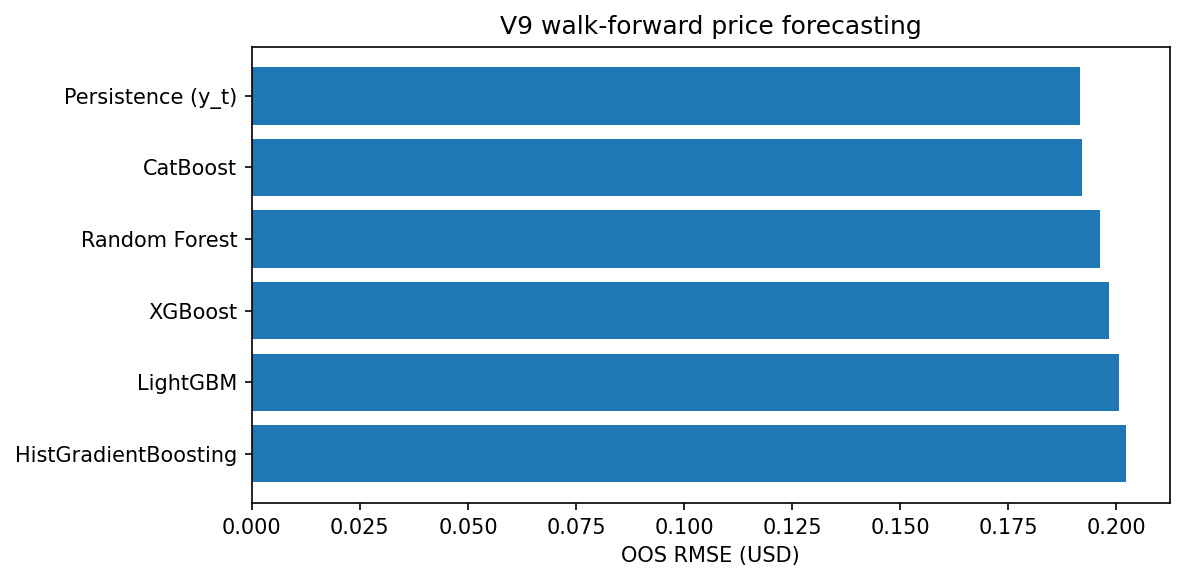

In [5]:
reg = pd.read_csv(D/'model_evaluation_results.csv')
display(reg.round(5))
cat=reg.set_index('model').loc['CatBoost']; pers=reg.set_index('model').loc['Persistence (y_t)']
print(f'CatBoost RMSE={cat.RMSE_micro:.5f}; Persistence={pers.RMSE_micro:.5f}; skill={cat.SS_RMSE:+.2%}; HAC DM p={cat.DM_pvalue:.3f}')
print('Month bootstrap skill CI:', cat.SS_RMSE_CI95)
print('Price R² is not percentage accuracy. Residual R²:',round(cat.R2_delta,5))
display(Image(filename=str(ROOT/'figures'/'model_comparison.png'),width=750))

**Interpretation:** persistence slightly beats the pre-specified CatBoost system in pooled RMSE. The confidence interval crosses zero and the month-level HAC test does not establish reliable superiority. DM weights month losses equally whereas pooled RMSE weights individual rows; signs can differ. CatBoost's high level-price R² largely reflects persistence. Do not present the point model as the best overall method.

In [6]:
display(pd.read_csv(D/'model_eval_by_country.csv').round(5))
display(pd.read_csv(D/'model_eval_by_commodity.csv').round(5))
display(pd.read_csv(D/'model_eval_by_pricetype.csv').round(5))

,countryiso3,n,MAE_micro,RMSE_micro,sMAPE_micro,R2_micro,R2_delta,MAE_macro,Persistence_MAE,Persistence_RMSE,SS_RMSE,DM_stat,DM_pvalue
0,IDN,3780,0.06969,0.14311,3.17477,0.99745,0.02343,0.06969,0.06736,0.14484,0.01195,-1.03199,0.30208
1,KHM,2722,0.08106,0.15474,4.25087,0.99168,0.02240,0.08106,0.07943,0.15670,0.01245,-1.30471,0.19199
2,LAO,3642,0.11819,0.29484,3.89676,0.97675,0.00728,0.11819,0.11036,0.29593,0.00368,-0.11830,0.90583
3,MMR,84,0.15421,0.72220,8.48285,0.58234,-0.02702,0.15421,0.14833,0.71719,-0.00698,1.08021,0.28005
4,PHL,15793,0.10810,0.16818,2.72430,0.99470,-0.03068,0.10810,0.10407,0.16566,-0.01521,1.28101,0.20019
5,THA,18,0.03039,0.04482,2.96490,0.99445,-0.01584,0.03039,0.02889,0.04460,-0.00507,0.09160,0.92702
6,TLS,197,0.14407,0.30854,9.87675,0.92642,0.11177,0.14407,0.14409,0.32738,0.05756,-1.69002,0.09102


,commodity_group,n,MAE_micro,RMSE_micro,sMAPE_micro,R2_micro,R2_delta,MAE_macro,Persistence_MAE,Persistence_RMSE,SS_RMSE,DM_stat,DM_pvalue
0,Beef Meat,5556,0.15303,0.24706,2.36084,0.95277,-0.03111,0.15703,0.14498,0.24331,-0.01541,-0.56404,0.57272
1,Chicken Meat,4645,0.12409,0.21908,3.72581,0.86080,0.01852,0.12565,0.12099,0.22115,0.00935,-1.33055,0.18334
2,Cooking Oil,1824,0.06790,0.20359,4.46737,0.78798,-0.00840,0.15453,0.06418,0.20291,-0.00334,0.37268,0.70938
3,Pork Meat,5643,0.16017,0.23714,3.18707,0.93141,0.00390,0.16143,0.15674,0.23775,0.00260,-0.13393,0.89346
4,Rice,8568,0.02442,0.03968,3.14469,0.94606,-0.06392,0.03831,0.02202,0.03848,-0.03139,2.68744,0.00720


,pricetype,n,MAE_micro,RMSE_micro,sMAPE_micro,R2_micro,R2_delta,MAE_macro,Persistence_MAE,Persistence_RMSE,SS_RMSE,DM_stat,DM_pvalue
0,Retail,24806,0.10285,0.19417,3.11018,0.99364,-0.00718,0.11284,0.09868,0.19348,-0.00358,-0.79898,0.42430
1,Wholesale,1430,0.07845,0.15249,4.43984,0.99112,0.02725,0.04545,0.07689,0.15479,0.01485,-1.46590,0.14268


## 4. Alert evaluation and uncertainty
Binary metrics use the actual hybrid rule; PR-AUC and ROC-AUC are reserved for continuous scores. Baselines are logistic regression, historical shock rate and lagged momentum, plus forecast-only and score-only. Thresholds are chosen on calibration data, not pooled test. CIs resample whole months to preserve cross-sectional dependence; they do not fully model serial dependence.

,method,Precision,Recall,F1,FPR,FDR,PR_AUC,ROC_AUC,TP,FP,FN,TN,Lift,Alerts_Per_Month
0,Hybrid_Operational_Alert,0.16921,0.19689,0.18200,0.09068,0.83079,NaN,NaN,443,2175,1807,21811,1.97310,33.56410
1,Stage2_Only,0.16771,0.19067,0.17845,0.08876,0.83229,0.13197,0.60832,429,2129,1821,21857,1.95556,32.79487
2,Forecast_Only,0.26087,0.01067,0.02050,0.00283,0.73913,0.10273,0.51813,24,68,2226,23918,3.04186,1.17949
3,HistoricalShockRate,0.11653,0.26844,0.16252,0.19090,0.88347,0.10705,0.56282,604,4579,1646,19407,1.35885,66.44872
4,LaggedMomentum,0.13215,0.12933,0.13073,0.07967,0.86785,0.09833,0.49573,291,1911,1959,22075,1.54096,28.23077
5,LogisticRegression,0.17962,0.20133,0.18986,0.08626,0.82038,0.13453,0.60085,453,2069,1797,21917,2.09444,32.33333


Hybrid precision=16.92%, recall=19.69%, FPR=9.07%, lift=1.97×
Interval coverage=78.00% (target 80%); mean width=0.2649 USD
Precision CI: [0.1346, 0.2098] Recall CI: [0.1251, 0.2634]
Stage-2 PR-AUC=0.132, ROC-AUC=0.608


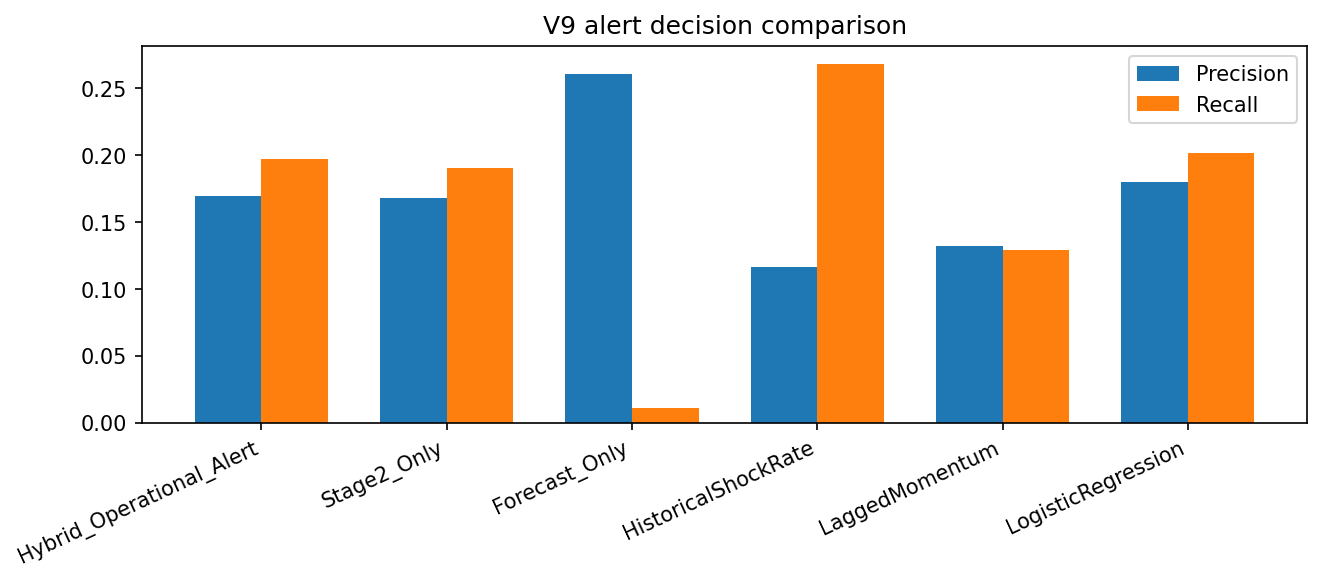

In [7]:
shock=pd.read_csv(D/'model_eval_shock_classification.csv')
display(shock[['method','Precision','Recall','F1','FPR','FDR','PR_AUC','ROC_AUC','TP','FP','FN','TN','Lift','Alerts_Per_Month']].round(5))
hy=shock.set_index('method').loc['Hybrid_Operational_Alert']; st=shock.set_index('method').loc['Stage2_Only']
print(f'Hybrid precision={hy.Precision:.2%}, recall={hy.Recall:.2%}, FPR={hy.FPR:.2%}, lift={hy.Lift:.2f}×')
print(f'Interval coverage={hy.Overall_PICP_P10_P90:.2%} (target 80%); mean width={hy.Mean_Interval_Width:.4f} USD')
print('Precision CI:',hy.Precision_CI95,'Recall CI:',hy.Recall_CI95)
print(f'Stage-2 PR-AUC={st.PR_AUC:.3f}, ROC-AUC={st.ROC_AUC:.3f}')
display(Image(filename=str(ROOT/'figures'/'shock_classification.png'),width=820))

**Interpretation:** many alerts are false and most actual shocks are missed. Logistic regression is competitive and has slightly higher F1. The system is a screening tool for further verification, not a guaranteed alert or automatic policy trigger. Interval coverage is an observed backtest outcome; temporal dependence prevents an unconditional guarantee.

## 5. Feature ablation and exact-model explainability
Each ablation shares the same fit periods and fold-specific CatBoost parameters; only feature groups change. All ML configurations include the three encoded categories. This tests contribution, not a claim that every feature group improves results. SHAP is computed on a deterministic holdout sample using the exact official frozen CatBoost point model.

,feature_set,n_numeric_features,n,MAE_micro,RMSE_micro,sMAPE_micro,R2_micro,R2_delta,MAE_macro,Persistence_MAE,Persistence_RMSE,SS_RMSE,DM_stat,DM_pvalue
0,Persistence (y_t),0,26236,0.09749,0.19157,2.99810,0.99381,-0.00003,0.09750,0.09749,0.19157,0.00000,NaN,NaN
1,Lag + current price,6,26236,0.10141,0.19381,3.10983,0.99366,-0.02359,0.09967,0.09749,0.19157,-0.01171,-0.34277,0.73177
2,+ Rolling / momentum / seasonality,18,26236,0.10266,0.19377,3.21564,0.99366,-0.02309,0.10280,0.09749,0.19157,-0.01146,-0.16199,0.87131
3,+ FX,21,26236,0.10148,0.19205,3.18924,0.99377,-0.00506,0.10131,0.09749,0.19157,-0.00251,-0.75116,0.45256
4,Full FoodShock (+ ASEAN spillover),23,26236,0.10152,0.19213,3.18265,0.99377,-0.00590,0.10081,0.09749,0.19157,-0.00293,-0.74391,0.45693


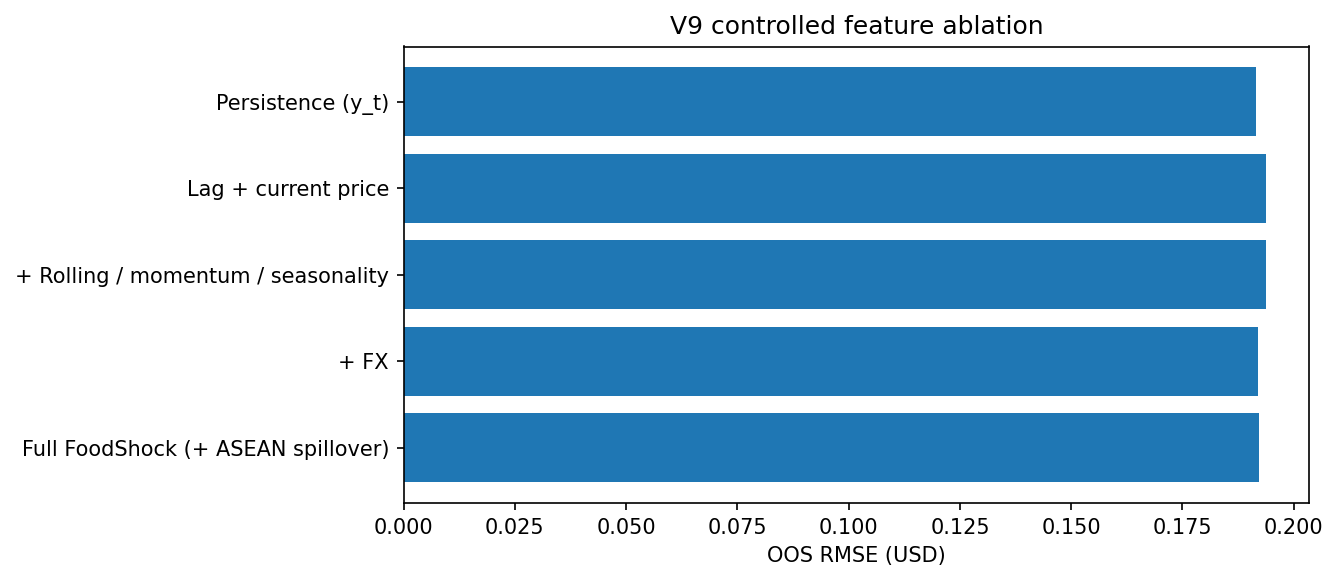

,feature,mean_abs_shap
0,usdprice,0.104609
1,month_cos,0.020328
2,lag_1,0.017974
3,lag_2,0.015914
4,lag_3,0.013394
5,rolling_max_6,0.010529
6,rolling_mean_3,0.010202
7,fx_pct_3m,0.009962
8,month_sin,0.007664
9,rolling_mean_6,0.007625


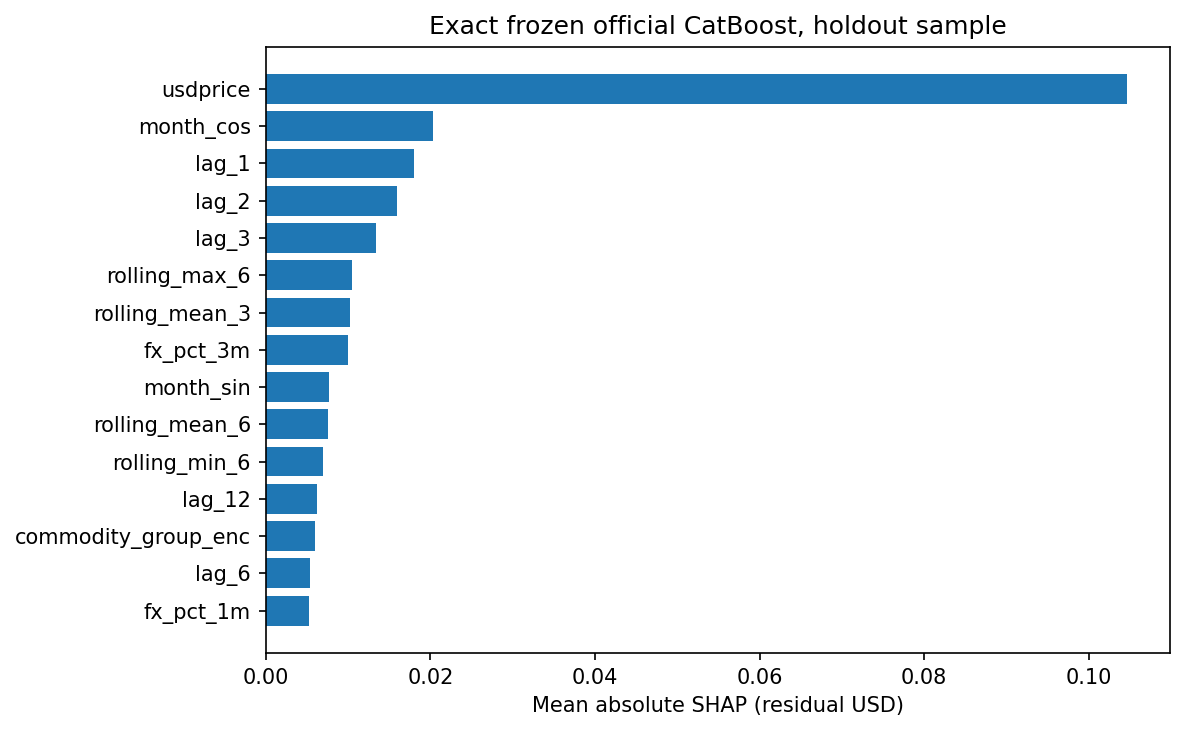

In [8]:
display(pd.read_csv(D/'v9_feature_ablation.csv').round(5))
display(Image(filename=str(ROOT/'figures'/'feature_ablation.png'),width=820))
display(pd.read_csv(D/'v9_shap_importance.csv').head(10))
display(Image(filename=str(ROOT/'figures'/'shap_summary.png'),width=820))

## 6. Frozen official holdout vs custom training
The official application what-if bundle is a CatBoost residual model with its own fit/calibration and 18-month holdout (June 2024–November 2025). Its metrics are not pooled into the seven-fold benchmark. It is not a new production model fit on all available data. Custom training uses the same shared engine and a separate threshold. Direct mode does not invent uncertainty bounds.

In [9]:
print('Official parameters:',M['official_params'])
print('Model threshold:',M['official_threshold'],'qcal:',M['official_qcal'])
display(pd.Series(M['official_holdout_metrics'],name='Official 18-month holdout'))

Official parameters: {'n_estimators': 112, 'max_depth': 6, 'learning_rate': 0.03470870428658689}
Model threshold: 0.7 qcal: 0.010302895514810154


model                CatBoost (Residual)
MAE                             0.099639
RMSE                            0.174006
sMAPE                            2.67677
R2                              0.994423
Persistence_MAE                 0.092876
Persistence_RMSE                0.171217
Persistence_sMAPE                2.50827
Persistence_R2                    0.9946
PICP_P10_P90                    0.799483
n_train                            10834
n_calibration                       9268
n_test                              6957
Precision                         0.1875
Recall                          0.028846
F1                                  0.05
FPR                              0.00795
FDR                               0.8125
PR_AUC                          0.107671
ROC_AUC                         0.650393
TP                                    12
FP                                    52
FN                                   404
TN                                  6489
Name: Official 1

## 7. Live historical inference parity
Select a real OOS row and load the exact fold model. The code below uses the same inference and alert functions as Streamlit. Actual next-month data is displayed only after inference.

In [10]:
oos=pd.read_csv(D/'v9_oos_predictions.csv',parse_dates=['date'])
c=oos[oos.model=='CatBoost'].copy()
example=c[(c.countryiso3=='IDN') & (c.commodity_group=='Rice')].iloc[0]
bundle=load_bundle(str(example.fold),D)
reference=panel[(panel.series_id==example.series_id)&(panel.date==example.date)].iloc[0]
pred=predict_two_stage(bundle,reference.to_dict())
np.testing.assert_allclose([pred['y_hat'],pred['y_p10'],pred['y_p90'],pred['shock_proba']],[example.predicted,example.lower,example.upper,example.score],rtol=1e-8,atol=1e-8)
assert pred['alert']==bool(example.alert)
label,_=classify_shock(pred['change'],pred['shock_proba'],bundle['threshold'])
print('Live inference matches stored OOS prediction:', example.series_id, example.date.date())
display(pd.Series({'current':pred['y_t'],'next forecast':pred['y_hat'],'actual next':example.actual,'lower':pred['y_p10'],'upper':pred['y_p90'],'risk score':pred['shock_proba'],'threshold':bundle['threshold'],'alert':label}))

Live inference matches stored OOS prediction: IDN|National Average|Rice|Retail|actual|KG 2019-06-01


current                             0.97
next forecast                   0.973719
actual next                          1.0
lower                           0.940785
upper                           0.991019
risk score                       0.33574
threshold                            0.6
alert            WASPADA / ELEVATED RISK
dtype: object

## 8. Reproduction and application
Run `python src/run_v9.py --trials 25` to regenerate benchmark artifacts; `python src/build_report.py` to regenerate the report. Run `python -m unittest discover -s tests -v` to verify shared inference, dataset, time splits, scenario features, and metric parity. Run `python -m streamlit run app.py` after dependencies are installed. The source code and model-ready dataset meet the preliminary deliverable format described in the supplied guidebook; final presentation and Q&A are outside this package's scope.

**Limitations:** original raw WFP snapshot/license absent; retrospective series eligibility, imbalanced country support, timing assumptions, poor shock recall, no calibrated event probability, and no real user-impact validation. Browser-level Streamlit testing was not possible in the build environment. The application core and saved model replays were tested. See `VALIDATION_REPORT.md`, `RESULTS.md`, and `docs/DATA_SOURCES.md`.